# Imports

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Question 1

Calculate $\eta$ for thermal neutrons as a function of uranium enrichment and plot your results. Use the uranium data from the table provided in the cell below

In [34]:
nu_U235 = 2.43
sigma_f_U235 = 580
sigma_c_U235 = 107

nu_U238 = 0
sigma_f_U238 = 0
sigma_c_U238 = 2.75

# Cross sections are in barns, doesn't matter about converting as it comes out as a factor and simplifies regardless

In [35]:
def eta_enriched(e, nu_fi, sigma_f_fi, sigma_c_fi, nu_fe, sigma_f_fe, sigma_c_fe):
    sigma_a_fi = sigma_f_fi + sigma_c_fi
    sigma_a_fe = sigma_f_fi + sigma_c_fe

    eta = (e * nu_fi * sigma_f_fi + (1-e) * nu_fe * sigma_f_fe)/(e * sigma_a_fi + (1-e) * sigma_a_fe)

    return eta

In [36]:
enrichments = np.linspace(0,1,101)

eta_enrichment_data = eta_enriched(enrichments, nu_U235, sigma_f_U235, sigma_c_U235, nu_U238, sigma_f_U238,sigma_c_U238)

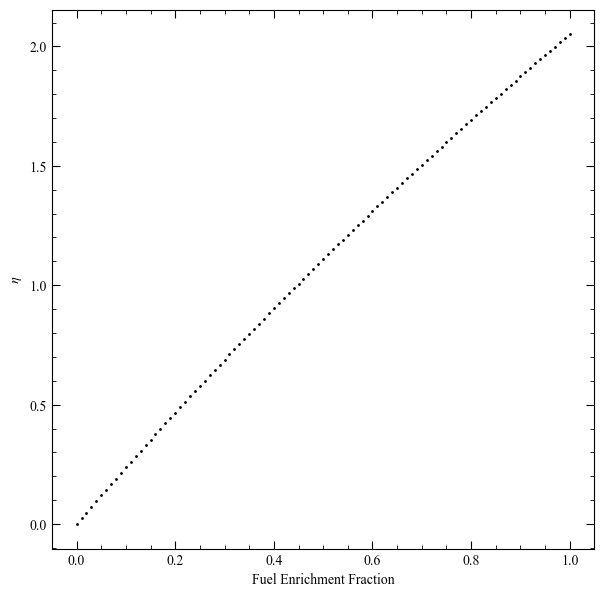

In [39]:
plt.rcParams.update({
    "font.family": "Times New Roman",  # Use Times New Roman for all text
    "mathtext.fontset": "custom",      # Use custom font for math
    "mathtext.rm": "Times New Roman",  # Roman font in math
    "mathtext.it": "Times New Roman:italic",  # Italic font in math
    "mathtext.bf": "Times New Roman:bold",    # Bold font in math
    "text.usetex": False
})

fig = plt.figure(figsize = (7,7))

gs = fig.add_gridspec(
    1, 1,
    height_ratios=[1],
    hspace=0.0
)

ax_main = fig.add_subplot(gs[0])

ax_main.scatter(enrichments, eta_enrichment_data,
            s=1, color = "black")

ax_main.set_xlabel("Fuel Enrichment Fraction")
ax_main.set_ylabel("$\\eta$")

for ax in [ax_main]:
    ax.minorticks_on()
    ax.tick_params(which='major', size=6, direction='in',
                   right=True, top=True)
    ax.tick_params(which='minor', size=3, direction='in',
                   right=True, top=True)
    for label in ax.get_xticklabels()+ ax.get_yticklabels():
        label.set_bbox(dict(
            facecolor="white",
            edgecolor="none",
            pad=1.0
        ))

plt.show()